# Feature Engineering Experiments

## Objective

The objective of this notebook is to investigate whether different TF-IDF
configurations can improve the performance of the Linear Support Vector
Machine (Linear SVM) classifier.

The baseline model uses:
- TF-IDF vectorization
- Unigrams and bigrams
- min_df = 2
- max_df = 0.95
- LinearSVC classifier

We will experiment with different minimum document frequencies and
sublinear term frequency scaling while keeping the classifier and
cross-validation methodology fixed.

All experiments will use the training dataset and stratified 5-fold
cross-validation. The held-out test dataset will not be used for model
selection.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

In [3]:
train_df = pd.read_csv("../data/processed/train.csv")

X_train = train_df["text"].astype(str)
y_train = train_df["target"].astype(int)

print("Training samples:", len(X_train))
print("Label distribution:")
print(y_train.value_counts())

Training samples: 32328
Label distribution:
target
0    16172
1    16156
Name: count, dtype: int64


In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "roc_auc": "roc_auc"
}

In [5]:
def evaluate_tfidf_config(config_name, min_df=2, sublinear_tf=False):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=min_df,
            max_df=0.95,
            sublinear_tf=sublinear_tf
        )),
        ("classifier", LinearSVC(
            max_iter=5000,
            random_state=42
        ))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    return {
        "Configuration": config_name,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "macro_f1_mean": scores["test_macro_f1"].mean(),
        "macro_f1_std": scores["test_macro_f1"].std(),
        "balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
        "balanced_accuracy_std": scores["test_balanced_accuracy"].std(),
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std()
    }

In [6]:
experiments = [
    ("Baseline (min_df=2)", 2, False),
    ("min_df=1", 1, False),
    ("min_df=3", 3, False),
    ("min_df=5", 5, False),
    ("Sublinear TF", 2, True)
]

experiment_results = []

for name, min_df, sublinear_tf in experiments:
    print(f"Running: {name}")

    result = evaluate_tfidf_config(
        config_name=name,
        min_df=min_df,
        sublinear_tf=sublinear_tf
    )

    experiment_results.append(result)

experiment_df = pd.DataFrame(experiment_results)

experiment_df

Running: Baseline (min_df=2)
Running: min_df=1
Running: min_df=3
Running: min_df=5
Running: Sublinear TF


,Configuration,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std
0,Baseline (min_df=2),0.943949,0.001281,0.943946,0.001281,0.943945,0.001281,0.986693,0.000330
1,min_df=1,0.942186,0.001914,0.942181,0.001914,0.942182,0.001914,0.985401,0.000305
2,min_df=3,0.943733,0.001003,0.943730,0.001003,0.943729,0.001003,0.986726,0.000338
3,min_df=5,0.942434,0.001350,0.942432,0.001350,0.942431,0.001350,0.986588,0.000255
4,Sublinear TF,0.946115,0.001706,0.946110,0.001705,0.946110,0.001705,0.987528,0.000227


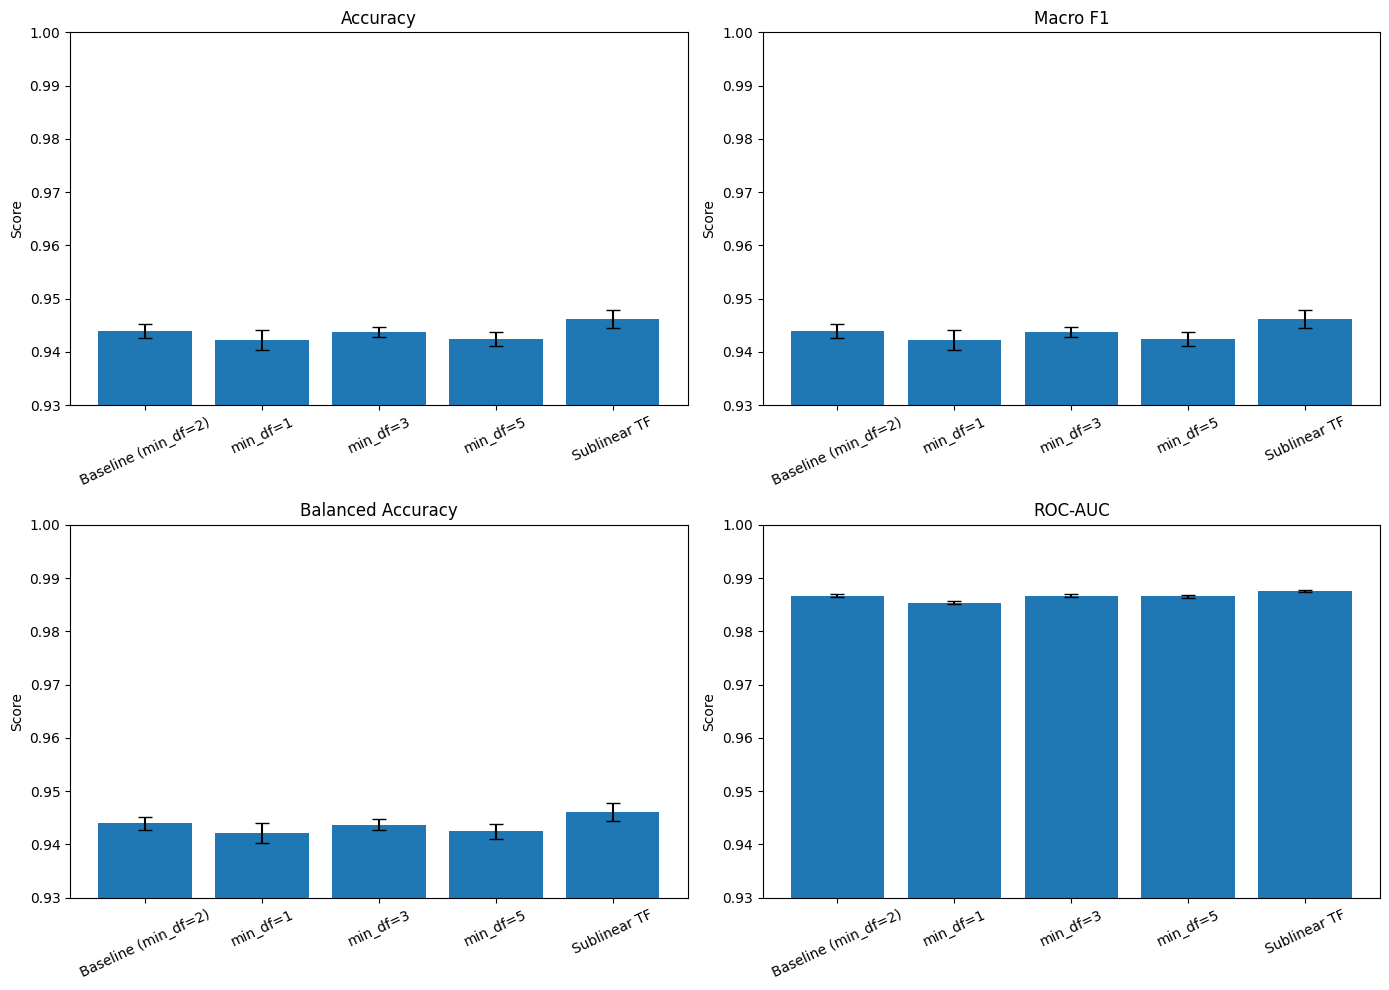

In [7]:
metrics = [
    ("accuracy_mean", "accuracy_std", "Accuracy"),
    ("macro_f1_mean", "macro_f1_std", "Macro F1"),
    ("balanced_accuracy_mean", "balanced_accuracy_std", "Balanced Accuracy"),
    ("roc_auc_mean", "roc_auc_std", "ROC-AUC")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (mean_col, std_col, title) in zip(axes, metrics):

    ax.bar(
        experiment_df["Configuration"],
        experiment_df[mean_col],
        yerr=experiment_df[std_col],
        capsize=5
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_ylim(0.93, 1.0)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()

plt.savefig(
    "../results/figures/feature_experiment_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
experiment_df.to_csv(
    "../results/metrics/feature_experiment_results.csv",
    index=False
)

print("Feature experiment results saved successfully.")

Feature experiment results saved successfully.


In [9]:
best_experiment = experiment_df.loc[
    experiment_df["macro_f1_mean"].idxmax()
]

print("Best configuration:", best_experiment["Configuration"])
print(f"Accuracy: {best_experiment['accuracy_mean']:.4f}")
print(f"Macro F1: {best_experiment['macro_f1_mean']:.4f}")
print(f"Balanced Accuracy: {best_experiment['balanced_accuracy_mean']:.4f}")
print(f"ROC-AUC: {best_experiment['roc_auc_mean']:.4f}")

Best configuration: Sublinear TF
Accuracy: 0.9461
Macro F1: 0.9461
Balanced Accuracy: 0.9461
ROC-AUC: 0.9875


## Conclusion

The feature engineering experiments investigated the effect of minimum
document frequency and sublinear term frequency scaling on the Linear SVM
classifier.

The results showed that:

- Reducing min_df to 1 slightly decreased model performance, suggesting
  that including very rare terms may introduce noise.
- Increasing min_df to 3 or 5 did not improve performance over the baseline.
- Enabling sublinear term frequency scaling improved all four evaluation
  metrics.

The best configuration was the Linear SVM with unigram and bigram TF-IDF,
min_df = 2, max_df = 0.95, and sublinear_tf = True.

It achieved:
- Accuracy: 94.61%
- Macro F1: 94.61%
- Balanced Accuracy: 94.61%
- ROC-AUC: 98.75%

The improvement over the baseline was modest, but consistent across the
reported metrics. Therefore, the sublinear TF configuration will be
carried forward as the leading candidate for subsequent analysis.

These results are based on cross-validation within the training dataset
and do not establish performance on reviews from arbitrary real-world
sources.